<a href="https://colab.research.google.com/github/San-Maansson/Machine_Learning/blob/main/Pytorch_ddata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, precision_recall_curve, confusion_matrix
)

In [2]:
# ----------------------
# 1. Generate Dummy Data
# ----------------------
# Set random seeds for reproducibility
torch.manual_seed(0)
np.random.seed(0)

# Regression data
y_true_reg = torch.linspace(0, 10, steps=100) + torch.randn(100) * 0.5
y_pred_reg = y_true_reg + torch.randn(100) * 0.8

# Classification data
y_true_cls = torch.randint(0, 2, (200,))
y_scores = torch.sigmoid(torch.randn(200))
y_pred_cls = (y_scores > 0.5).long()

# Convert to NumPy for sklearn metrics
y_true_reg_np = y_true_reg.numpy()
y_pred_reg_np = y_pred_reg.numpy()
y_true_cls_np = y_true_cls.numpy()
y_scores_np = y_scores.numpy()
y_pred_cls_np = y_pred_cls.numpy()


In [3]:
# ----------------------
# 2. Compute Regression Metrics
# ----------------------
mse = mean_squared_error(y_true_reg_np, y_pred_reg_np)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true_reg_np, y_pred_reg_np)
r2 = r2_score(y_true_reg_np, y_pred_reg_np)

print("Regression Metrics:")
print(f"MSE: {mse:.3f} | RMSE: {rmse:.3f}")
print(f"MAE: {mae:.3f} | R²: {r2:.3f}\n")

# ----------------------
# 3. Compute Classification Metrics
# ----------------------
accuracy = accuracy_score(y_true_cls_np, y_pred_cls_np)
precision = precision_score(y_true_cls_np, y_pred_cls_np, zero_division=0)
recall = recall_score(y_true_cls_np, y_pred_cls_np, zero_division=0)
f1 = f1_score(y_true_cls_np, y_pred_cls_np, zero_division=0)
fpr, tpr, _ = roc_curve(y_true_cls_np, y_scores_np)
roc_auc = auc(fpr, tpr)
prec_curve, rec_curve, _ = precision_recall_curve(y_true_cls_np, y_scores_np)
cm = confusion_matrix(y_true_cls_np, y_pred_cls_np)

print("Classification Metrics:")
print(f"Accuracy: {accuracy:.3f} | Precision: {precision:.3f}")
print(f"Recall: {recall:.3f} | F1: {f1:.3f} | AUC: {roc_auc:.3f}\n")

Regression Metrics:
MSE: 0.560 | RMSE: 0.748
MAE: 0.614 | R²: 0.936

Classification Metrics:
Accuracy: 0.505 | Precision: 0.564
Recall: 0.509 | F1: 0.535 | AUC: 0.523



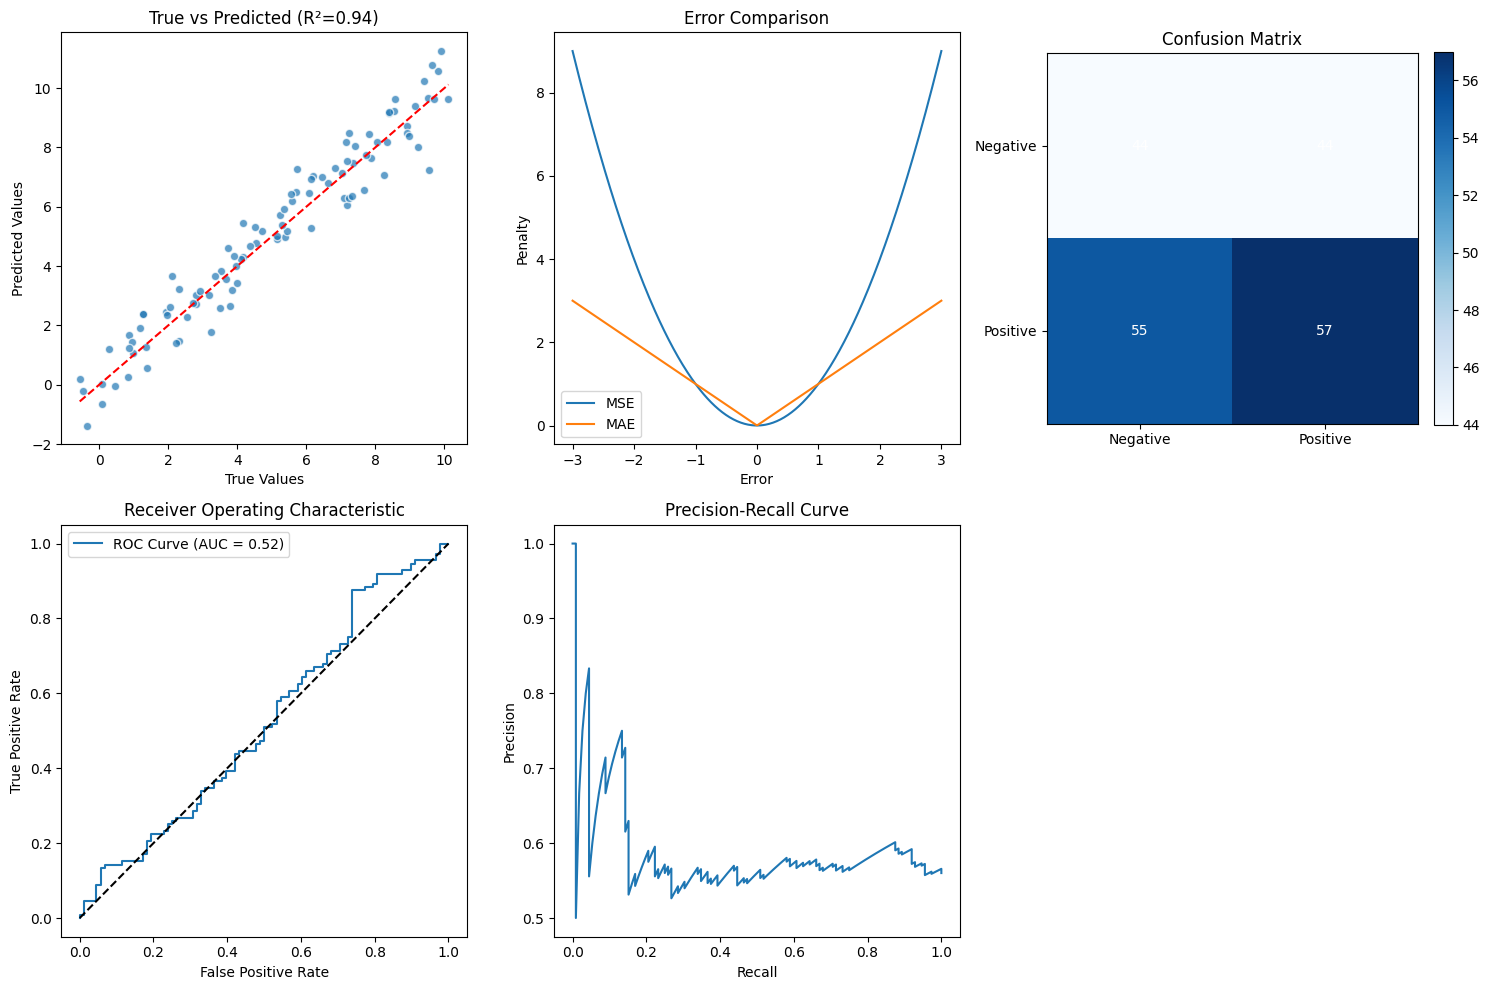

In [4]:
# ----------------------
# 4. Visualization
# ----------------------
plt.figure(figsize=(15, 10))

# Regression Plots
plt.subplot(2, 3, 1)
plt.scatter(y_true_reg_np, y_pred_reg_np, alpha=0.7, edgecolors='w')
plt.plot([y_true_reg_np.min(), y_true_reg_np.max()],
         [y_true_reg_np.min(), y_true_reg_np.max()], '--r')
plt.title(f"True vs Predicted (R²={r2:.2f})")
plt.xlabel("True Values")
plt.ylabel("Predicted Values")

plt.subplot(2, 3, 2)
errors = np.linspace(-3, 3, 400)
plt.plot(errors, errors**2, label='MSE')
plt.plot(errors, np.abs(errors), label='MAE')
plt.title("Error Comparison")
plt.xlabel("Error")
plt.ylabel("Penalty")
plt.legend()

# Classification Plots
plt.subplot(2, 3, 3)
plt.imshow(cm, cmap='Blues', interpolation='nearest')
plt.title("Confusion Matrix")
plt.colorbar(fraction=0.046, pad=0.04)
plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.subplot(2, 3, 4)
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], '--k')
plt.title("Receiver Operating Characteristic")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.subplot(2, 3, 5)
plt.plot(rec_curve, prec_curve)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.tight_layout()
plt.show()